# Лабораторная работа 1

**Вариант 4.** 

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
random.seed(42)
plt.rcParams['image.cmap'] = 'gray'

## 1. Классификация данных методом k ближайших соседей ( kNN)

1.1 Скачайте данные в соответсвии с заданием.

CIFAR-10 по ссылке https://www.cs.toronto.edu/~kriz/cifar.html
или используйте  команду !bash get_datasets.sh (google colab, local ubuntu)

MNIST
sklearn.datasets import load_digits
digits = load_digits()

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
digits = load_digits()

In [3]:
X, Y = digits.data, digits.target
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.25, random_state=42, stratify=Y
)

1.2 Выведите несколько примеров изображений из обучающей выборки для каждого класса.



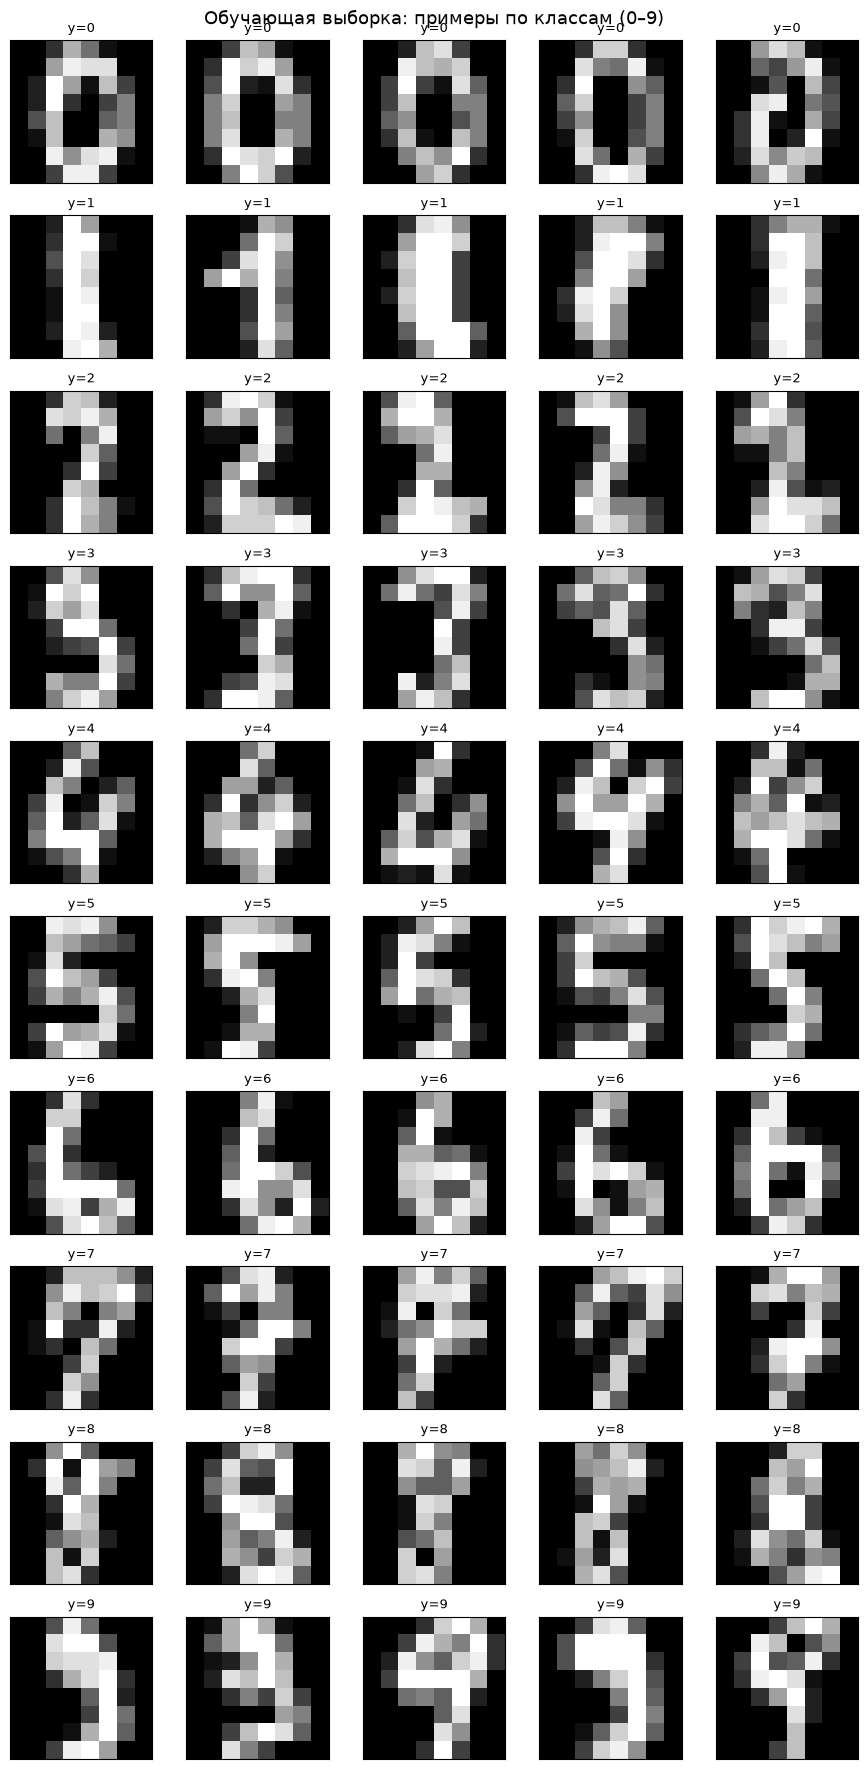

In [4]:
import numpy as np
import matplotlib.pyplot as plt

classes = np.unique(Y_train)
num_classes = len(classes)
samples_per_class = 5

np.random.seed(42)  

fig, axes = plt.subplots(num_classes, samples_per_class,
                         figsize=(samples_per_class * 1.8, num_classes * 1.8))

for cls_idx, cls in enumerate(classes):
    idxs = np.where(Y_train == cls)[0]
    chosen = np.random.choice(idxs, samples_per_class, replace=False)

    for i, idx in enumerate(chosen):
        ax = axes[cls_idx, i]
        ax.imshow(X_train[idx].reshape(8, 8), cmap='gray')
        ax.set_title(f'y={cls}', fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

plt.suptitle('Обучающая выборка: примеры по классам (0–9)', fontsize=13)
plt.tight_layout()
plt.show()

1.3 Разделите данные на обучающу и тестовую выборки (X_train, y_train, X_test, y_test). Преобразуйте каждое изображение в одномерный массив.

In [5]:
print('Обучение и тест:', X_train.shape, X_test.shape)

Обучение и тест: (1347, 64) (450, 64)


1.4 Напишите реализацию классификатора в скрипте /classifiers/k_nearest_neighbor.py и обучите его на сформированной выборке.

In [6]:
from scripts.classifiers.k_nearest_neighbor import KNearestNeighbor

classifier = KNearestNeighbor()
classifier.train(X_train, Y_train)

1.5 Выполните классификацию на тестовой выборке




In [7]:
Y_pred = classifier.predict(X_test, k=1)

1.6 Визуализируйте матрицу расстояний для каждого изображения из тестовой выборки до изображений из обучающей выборки.


Вычислим евклидовы расстояния тремя способами. В первом два цикла перебирают все пары изображений. Во втором цикл перебирает тестовые изображения, а NumPy вычисляет расстояния до всего обучающего набора за один шаг. В третьем используем равенство $\|x-y\|^2=\|x\|^2+\|y\|^2-2x^Ty$ сразу для всех пар. После сравнения построим общую тепловую карту.

Циклов: 2 | форма: (450, 1347) | время: 0.6613 с | макс. расхождение: 0.00e+00
Циклов: 1 | форма: (450, 1347) | время: 0.0863 с | макс. расхождение: 0.00e+00
Циклов: 0 | форма: (450, 1347) | время: 0.0246 с | макс. расхождение: 0.00e+00


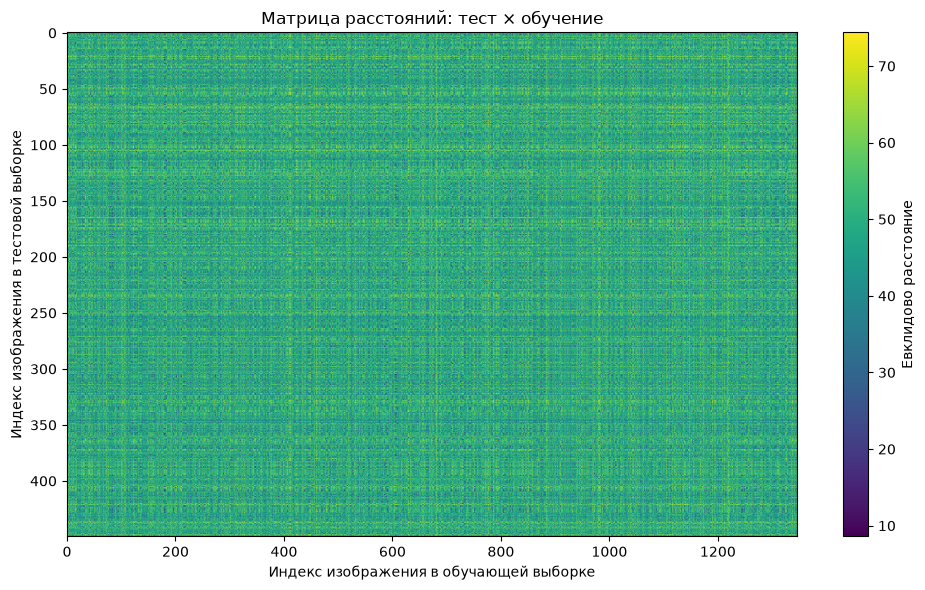

In [8]:
from time import perf_counter

reference = None
for loops in (2, 1, 0):
    start = perf_counter()
    dists = classifier.compute_distances(X_test, num_loops=loops)
    elapsed = perf_counter() - start
    assert dists.shape == (len(X_test), len(X_train))
    if reference is None:
        reference = dists
    np.testing.assert_allclose(dists, reference, atol=1e-10, rtol=1e-12)
    np.testing.assert_array_equal(classifier.predict_labels(dists, k=1), Y_pred)
    error = np.max(np.abs(dists - reference))
    print(f'Циклов: {loops} | форма: {dists.shape} | время: {elapsed:.4f} с | макс. расхождение: {error:.2e}')

plt.figure(figsize=(10, 6))
plt.imshow(dists, aspect='auto', cmap='viridis')
plt.colorbar(label='Евклидово расстояние')
plt.xlabel('Индекс изображения в обучающей выборке')
plt.ylabel('Индекс изображения в тестовой выборке')
plt.title('Матрица расстояний: тест × обучение')
plt.tight_layout()
plt.show()


1.7 Посчитайте долю правильно классифицированных изображений из тестовой выборки.


In [9]:
accuracy = np.mean(Y_pred == Y_test)
print(f'Accuracy: {accuracy:.4f}')
print(f'Правильно: {np.sum(Y_pred == Y_test)} из {len(Y_test)}')

Accuracy: 0.9844
Правильно: 443 из 450


1.8 Постройте график зависимости доли правильно классифицированных изображений от числа соседей, используемых при классификации.

k= 1 → accuracy: 0.9844
k= 2 → accuracy: 0.9844
k= 3 → accuracy: 0.9844
k= 4 → accuracy: 0.9822
k= 5 → accuracy: 0.9844
k= 6 → accuracy: 0.9800
k= 7 → accuracy: 0.9800
k= 8 → accuracy: 0.9778
k= 9 → accuracy: 0.9756
k=10 → accuracy: 0.9778
k=11 → accuracy: 0.9778
k=12 → accuracy: 0.9756
k=13 → accuracy: 0.9756
k=14 → accuracy: 0.9733
k=15 → accuracy: 0.9689
k=16 → accuracy: 0.9756
k=17 → accuracy: 0.9667
k=18 → accuracy: 0.9667
k=19 → accuracy: 0.9622
k=20 → accuracy: 0.9644


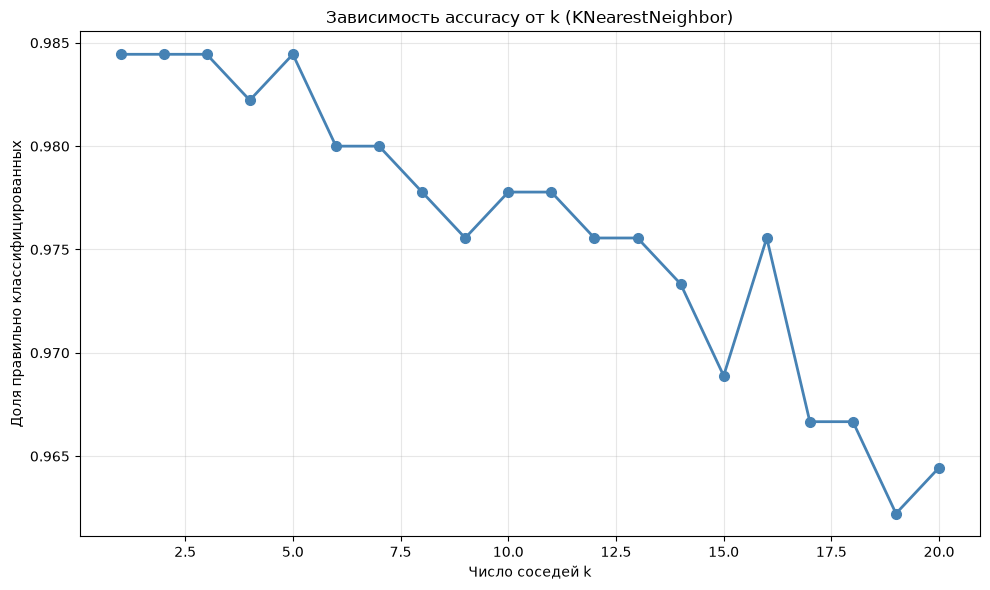

In [10]:
k_values = range(1, 21)
accuracies = []

for k in k_values:
    Y_pred = classifier.predict_labels(dists, k=k)
    acc = np.mean(Y_pred == Y_test)
    accuracies.append(acc)
    print(f'k={k:2d} → accuracy: {acc:.4f}')

plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, 'o-', color='steelblue',
         linewidth=2, markersize=7)
plt.xlabel('Число соседей k')
plt.ylabel('Доля правильно классифицированных')
plt.title('Зависимость accuracy от k (KNearestNeighbor)')
plt.grid(True, alpha=0.3)



plt.tight_layout()
plt.show()

1.9 Выберите лучшее значение параметра k на основе кросс-валидации.


In [11]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)
k_values = range(1, 21)

cv_accuracies = {k: [] for k in k_values}

for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train[train_idx], X_train[val_idx]
    Y_tr, Y_val = Y_train[train_idx], Y_train[val_idx]

    clf = KNearestNeighbor()
    clf.train(X_tr, Y_tr)

    fold_dists = clf.compute_distances(X_val)
    for k in k_values:
        Y_val_pred = clf.predict_labels(fold_dists, k=k)
        cv_accuracies[k].append(np.mean(Y_val_pred == Y_val))

# Средняя точность по фолдам для каждого k
mean_cv = {k: np.mean(v) for k, v in cv_accuracies.items()}
std_cv  = {k: np.std(v)  for k, v in cv_accuracies.items()}

best_k = max(mean_cv, key=mean_cv.get)
print(f'Лучшее k по кросс-валидации: {best_k} '
      f'(accuracy = {mean_cv[best_k]:.4f} ± {std_cv[best_k]:.4f})')

Лучшее k по кросс-валидации: 1 (accuracy = 0.9874 ± 0.0056)



1.10 Переобучите и протестируйте классификатор с использованием выбранного значения k.



In [12]:
classifier = KNearestNeighbor()
classifier.train(X_train, Y_train)


Y_pred = classifier.predict(X_test, k=best_k)

accuracy = np.mean(Y_pred == Y_test)
n_correct = np.sum(Y_pred == Y_test)
n_total = len(Y_test)

print(f'Лучшее k: {best_k}')
print(f'Accuracy на тестовой выборке: {accuracy:.4f} ({accuracy*100:.2f}%)')
print(f'Правильно: {n_correct} из {n_total}')
print(f'Ошибок: {n_total - n_correct}')

Лучшее k: 1
Accuracy на тестовой выборке: 0.9844 (98.44%)
Правильно: 443 из 450
Ошибок: 7


1.11 Сделайте выводы по результатам 1 части задания.

In [13]:
print(f'По пятифолдовой кросс-валидации выбрано k={best_k}. '
      f'Средняя точность {mean_cv[best_k]:.2%}, стандартное отклонение {std_cv[best_k]*100:.2f} п. п. '
      f'На тестовой выборке верно распознано {n_correct} из {n_total} ({accuracy:.2%}). '
      'Все три способа дали совпадающие матрицы расстояний и предсказания при k=1.')

По пятифолдовой кросс-валидации выбрано k=1. Средняя точность 98.74%, стандартное отклонение 0.56 п. п. На тестовой выборке верно распознано 443 из 450 (98.44%). Все три способа дали совпадающие матрицы расстояний и предсказания при k=1.


## 3.  Построение softmax-классификатора

3.1 Разделите данные на обучающую, тестовую и валидационную выборки. Преобразуйте каждое изображение в одномерный массив. Выведите размеры выборок.

In [14]:
X_train, X_val, Y_train, Y_val = train_test_split(
    X_train, Y_train, test_size=0.2, random_state=42, stratify=Y_train
)
print('Обучение, валидация, тест:', X_train.shape, X_val.shape, X_test.shape)

Обучение, валидация, тест: (1077, 64) (270, 64) (450, 64)


3.2 Проведите предварительную обработку данных, путем вычитания среднего изображения, рассчитанного  по обучающей выборке.

3.3 Чтобы далее не учитывать смещение (свободный член b), добавьте дополнитульную размерность к массиву данных и заполните ее единицами.

[0.00000000e+00 2.95264624e-01 5.21355617e+00 1.19025070e+01
 1.18133705e+01 5.78922934e+00 1.31476323e+00 1.03992572e-01
 5.57103064e-03 1.97493036e+00]


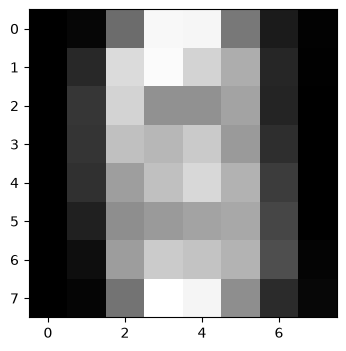

(1077, 65) (270, 65) (450, 65)


In [15]:
mean_image = np.mean(X_train, axis=0)
print(mean_image[:10])
plt.figure(figsize=(4,4))
plt.imshow(mean_image.reshape((8,8)), cmap="gray")
plt.show()
X_train = X_train.astype(np.float32)
X_val   = X_val.astype(np.float32)
X_test  = X_test.astype(np.float32)

X_train -= mean_image
X_val -= mean_image
X_test -= mean_image



X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_val = np.hstack([X_val, np.ones((X_val.shape[0], 1))])
X_test = np.hstack([X_test, np.ones((X_test.shape[0], 1))])



print(X_train.shape, X_val.shape, X_test.shape)

3.4 Реализуйте функции в classifiers/softmax.py




In [16]:
from scripts.classifiers.softmax import softmax_loss_naive
import time

W = np.random.randn(65, 10) * 0.0001
loss, grad = softmax_loss_naive(W, X_train, Y_train, 0.0)

print('loss: %f' % loss)
print('sanity check: %f' % (-np.log(0.1)))

loss: 2.301974
sanity check: 2.302585


3.5 Убедитесь, что вы верно реализовали расчет градиента, сравнив с реализацией численными методами (код приведен ниже).

In [17]:
loss, grad = softmax_loss_naive(W, X_train[:100], Y_train[:100], 0.0)


from scripts.gradient_check import grad_check_sparse
f = lambda w: softmax_loss_naive(w, X_train[:100], Y_train[:100], 0.0)[0]
grad_numerical = grad_check_sparse(f, W, grad, 10)


loss, grad = softmax_loss_naive(W, X_train[:100], Y_train[:100], 5e1)
f = lambda w: softmax_loss_naive(w, X_train[:100], Y_train[:100], 5e1)[0]
grad_numerical = grad_check_sparse(f, W, grad, 10)

numerical: 0.048436 analytic: 0.048436, relative error: 3.551644e-10
numerical: 0.120339 analytic: 0.120339, relative error: 3.864077e-10
numerical: -0.195813 analytic: -0.195813, relative error: 5.270842e-10
numerical: -0.352289 analytic: -0.352289, relative error: 4.068052e-12
numerical: 0.331768 analytic: 0.331768, relative error: 1.074716e-10
numerical: 0.213088 analytic: 0.213088, relative error: 2.015715e-10
numerical: 0.395140 analytic: 0.395140, relative error: 2.408093e-10
numerical: 0.040122 analytic: 0.040122, relative error: 1.509904e-09
numerical: 0.010023 analytic: 0.010023, relative error: 3.078391e-10
numerical: -0.121500 analytic: -0.121500, relative error: 7.604823e-10
numerical: 0.225788 analytic: 0.225788, relative error: 1.638060e-10
numerical: -0.270914 analytic: -0.270914, relative error: 1.450801e-10
numerical: 0.010280 analytic: 0.010280, relative error: 1.698258e-09
numerical: 1.108973 analytic: 1.108973, relative error: 5.597113e-11
numerical: 0.644725 analyt

3.6 Сравните softmax_loss_naive и softmax_loss_vectorized реализации

In [18]:
import time

tic = time.time()
loss_naive, grad_naive = softmax_loss_naive(W, X_train, Y_train, 0.000005)
toc = time.time()
print('naive loss: %e computed in %fs' % (loss_naive, toc - tic))

from scripts.classifiers.softmax import softmax_loss_vectorized
tic = time.time()
loss_vectorized, grad_vectorized = softmax_loss_vectorized(W, X_train, Y_train, 0.000005)
toc = time.time()
print('vectorized loss: %e computed in %fs' % (loss_vectorized, toc - tic))


grad_difference = np.linalg.norm(grad_naive - grad_vectorized, ord='fro')
print('Loss difference: %f' % np.abs(loss_naive - loss_vectorized))
print('Gradient difference: %f' % grad_difference)

naive loss: 2.301974e+00 computed in 0.023855s
vectorized loss: 2.301974e+00 computed in 0.001398s
Loss difference: 0.000000
Gradient difference: 0.000000


3.7 Реализуйте стохастический градиентный спуск в /classifiers/linear_classifier.py . Реализуйте методы train() и predict() и запустите следующий код

3.8 Обучите Softmax-классификатор и оцените accuracy на тестовой выборке.

In [19]:
from scripts.classifiers.linear_classifier import Softmax

softmax = Softmax()

tic = time.time()
loss_hist = softmax.train(
    X_train, Y_train,
    learning_rate=1e-2,
    reg=1e-5,
    num_iters=1500,
    batch_size=200,
    verbose=True
)
toc = time.time()
print('That took %fs' % (toc - tic))

y_train_pred = softmax.predict(X_train)
print('training accuracy: %f' % (np.mean(Y_train == y_train_pred), ))

y_val_pred = softmax.predict(X_val)
print('validation accuracy: %f' % (np.mean(Y_val == y_val_pred), ))

iteration 0 / 1500: loss 2.308797
iteration 100 / 1500: loss 0.172929
iteration 200 / 1500: loss 0.147824
iteration 300 / 1500: loss 0.106714
iteration 400 / 1500: loss 0.083352
iteration 500 / 1500: loss 0.068945
iteration 600 / 1500: loss 0.055843
iteration 700 / 1500: loss 0.054021
iteration 800 / 1500: loss 0.051417
iteration 900 / 1500: loss 0.044169
iteration 1000 / 1500: loss 0.049985
iteration 1100 / 1500: loss 0.041055
iteration 1200 / 1500: loss 0.037862
iteration 1300 / 1500: loss 0.034940
iteration 1400 / 1500: loss 0.024934
That took 0.165112s
training accuracy: 1.000000
validation accuracy: 0.970370


In [20]:
y_test_pred = softmax.predict(X_test)
test_accuracy = np.mean(Y_test == y_test_pred)
print('softmax on raw pixels final test set accuracy: %f' % test_accuracy)

softmax on raw pixels final test set accuracy: 0.955556


3.9 С помощью кросс-валидации выберите значения параметров скорости обучения и регуляризации. В кросс-валидации используйте обучающую и валидационную выборки. Оцените accuracy на тестовой выборке.

In [21]:
learning_rates = [0.001, 0.01]
regularization_strengths = [0.00001, 0.001]

In [22]:
best_val = -1
best_softmax = None

for lr in learning_rates:
    for reg in regularization_strengths:
        softmax = Softmax()
        softmax.train(X_train, Y_train, learning_rate=lr, reg=reg,
                      num_iters=1500, batch_size=200, verbose=False)
        
        y_train_pred = softmax.predict(X_train)
        train_acc = np.mean(Y_train == y_train_pred)
        
        y_val_pred = softmax.predict(X_val)
        val_acc = np.mean(Y_val == y_val_pred)
        
        if val_acc > best_val:
            best_lr, best_reg = lr, reg
            best_val = val_acc
            best_softmax = softmax

y_test_pred = best_softmax.predict(X_test)
test_acc = np.mean(Y_test == y_test_pred)
print('best validation accuracy: %f' % best_val)
print('test accuracy: %f' % test_acc)

best validation accuracy: 0.970370
test accuracy: 0.957778


3.10 Сделайте выводы по третьей части задания

In [23]:
print(f'Обе реализации Softmax дали расхождение градиентов {grad_difference:.2e}. '
      f'По валидационной точности выбраны шаг обучения {best_lr:g} и регуляризация {best_reg:g}. '
      f'Точность на валидации {best_val:.2%}, на тестовой выборке {test_acc:.2%}.')

Обе реализации Softmax дали расхождение градиентов 7.01e-15. По валидационной точности выбраны шаг обучения 0.01 и регуляризация 1e-05. Точность на валидации 97.04%, на тестовой выборке 95.78%.
